# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle

NETID = 'nraja3'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']
print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")

def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P

34 epochs over 864 days; median quoted error 2.33 km/s


## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


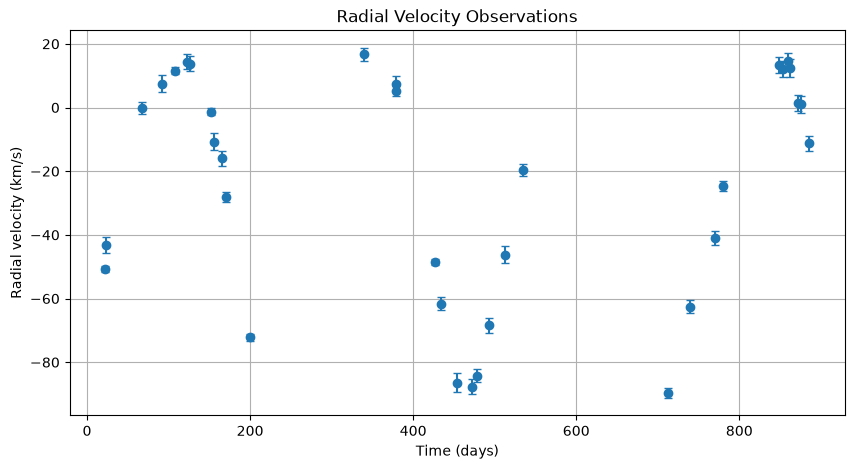

In [2]:
# Part 1: your work here
plt.figure(figsize=(10, 5))
plt.errorbar(t, rv, yerr=sig, fmt="o", capsize=3)
plt.xlabel("Time (days)")
plt.ylabel("Radial velocity (km/s)")
plt.title("Radial Velocity Observations")
plt.grid()
plt.show()

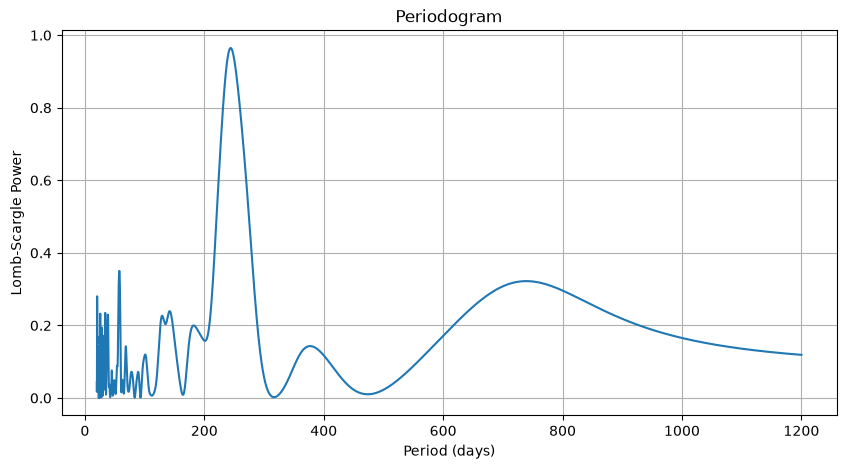

Candidate periods:
244.11 days
57.62 days
739.22 days


In [3]:
from scipy.signal import find_peaks

periods = np.linspace(20, 1200, 50000)
ls = LombScargle(t, rv, sig)
power = ls.power(1/periods)

plt.figure(figsize=(10, 5))
plt.plot(periods, power)
plt.xlabel("Period (days)")
plt.ylabel("Lomb-Scargle Power")
plt.title("Periodogram")
plt.grid()
plt.show()

peaks, _ = find_peaks(power, prominence=0.005)
peaks = sorted(peaks, key=lambda i: power[i], reverse=True)

candidates = []

for i in peaks:
    p = periods[i]
    if all(abs(p-x)/x > 0.08 for x in candidates):
        candidates.append(p)
    if len(candidates) == 3:
        break

print("Candidate periods:")
for p in candidates:
    print(round(p, 2), "days")

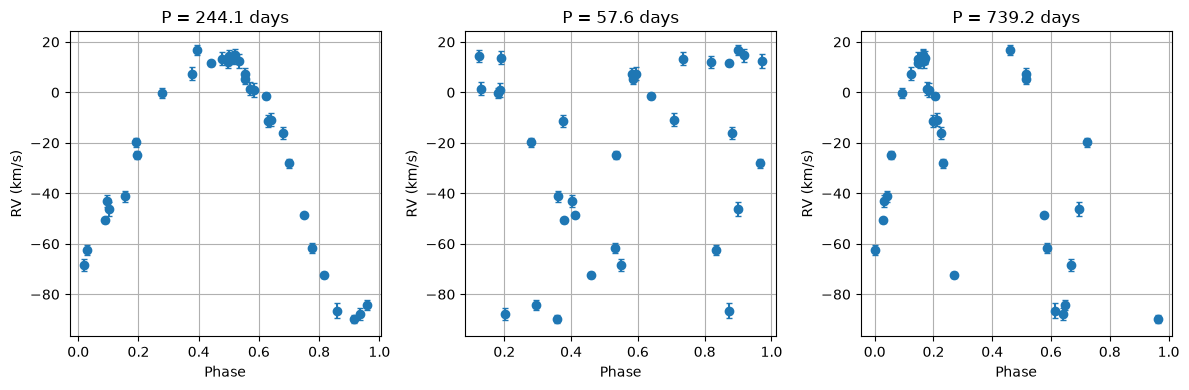

In [4]:
fig, axes = plt.subplots(1, len(candidates), figsize=(4*len(candidates), 4), squeeze=False)

for ax, p in zip(axes[0], candidates):
    phase = (t/p) % 1
    ax.errorbar(phase, rv, yerr=sig, fmt="o", capsize=2)
    ax.set_title(f"P = {p:.1f} days")
    ax.set_xlabel("Phase")
    ax.set_ylabel("RV (km/s)")
    ax.grid()

plt.tight_layout()
plt.show()

**ANSWER (a few sentences):**

The periodogram shows five possible periods at about 244.11, 57.62, 739.22, 20.5, and 141.97 days. The best one looks like 244.11 days because the points make a clearer pattern, while the other periods look more spread out. Lomb-Scargle uses a sine wave to find the period, but the star does not move at the same speed throughout its orbit, so the shape is not a perfect sine wave. Because of this, we cannot be completely sure of the period from this graph alone. The other peaks happen because there are large gaps in the data where we did not observe the star, making it harder to find the correct period.

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___, $\gamma = $ ___ $\pm$ ___ km/s, jitter $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$. Is your companion a black-hole candidate? One sentence.


In [5]:
# Part 2: your work here
tref = t.min()

def loglike(theta, y=rv, errors=sig):
    P, K, e, omega, q, gamma, logj = theta

    if P <= 0 or K <= 0 or e < 0 or e >= 1:
        return -np.inf

    Tp = tref + q*P
    model = kepler_rv(t, P, K, e, omega, Tp, gamma)
    var = errors**2 + np.exp(2*logj)

    return -0.5*np.sum((y-model)**2/var + np.log(2*np.pi*var))

fits = []

for p in candidates:
    best = None

    bounds0 = [
        (max(20, p*0.7), min(1200, p*1.3)),
        (0.01, 300),
        (0, 0.95),
        (-2*np.pi, 4*np.pi),
        (-0.5, 1.5),
        (rv.min()-150, rv.max()+150),
        (np.log(0.001), np.log(100))
    ]

    for e0 in [0.05, 0.4, 0.75]:
        for w0 in [0, np.pi/2, np.pi, 3*np.pi/2]:
            for q0 in [0, 0.25, 0.5, 0.75]:
                x0 = [p, max(np.std(rv), 1), e0, w0, q0, np.mean(rv), np.log(2)]

                fit = minimize(
                    lambda x: -loglike(x),
                    x0,
                    method="L-BFGS-B",
                    bounds=bounds0,
                    options={"maxiter": 2000}
                )

                if np.isfinite(fit.fun):
                    if best is None or fit.fun < best.fun:
                        best = fit

    if best is not None:
        fits.append(best)
        print(f"Starting period {p:.2f} days: logL = {-best.fun:.3f}")

fits.sort(key=lambda x: x.fun)

theta0 = fits[0].x

print("\nBest parameters:", theta0)
print("Best log-likelihood:", -fits[0].fun)

Starting period 244.11 days: logL = -87.443
Starting period 57.62 days: logL = -165.379
Starting period 739.22 days: logL = -154.645

Best parameters: [ 2.43832641e+02  5.12136010e+01  1.67996185e-01  8.84793590e+00
 -2.49289855e-01 -3.02432070e+01  8.48047940e-01]
Best log-likelihood: -87.44295768467924


Runner-up log-likelihood: -154.64451537393882
Mean acceptance fraction: 0.4872484375


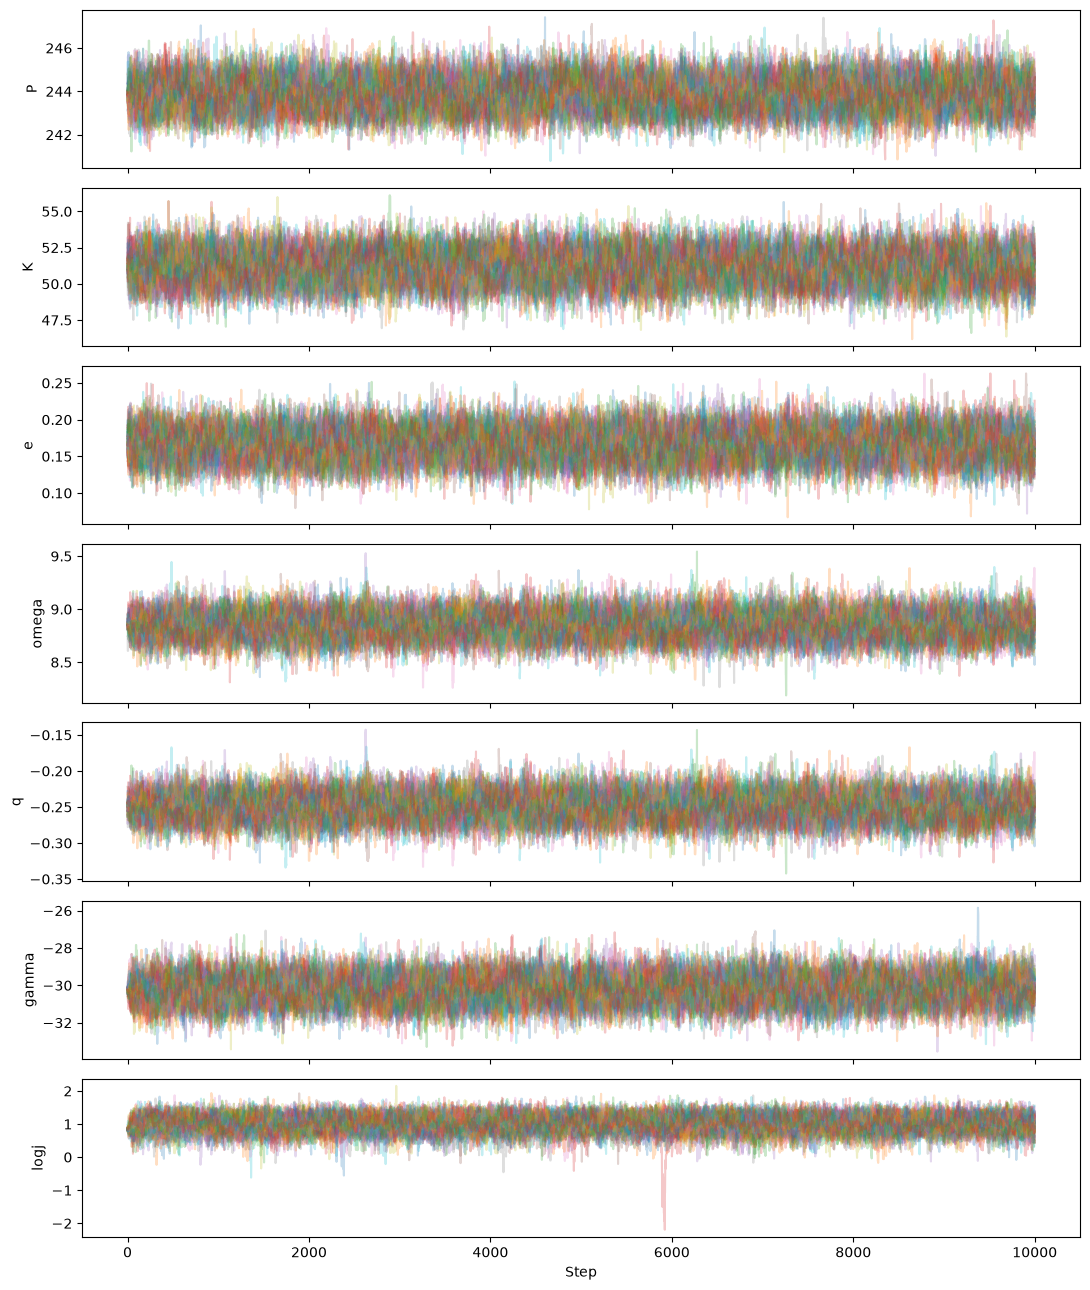

P: tau = 72.99
K: tau = 72.98
e: tau = 74.78
omega: tau = 70.84
q: tau = 72.59
gamma: tau = 69.78
logj: tau = 74.48
Chain length / maximum tau: 133.72662127936084
Burn-in: 373
Thinning: 34
Number of posterior samples: 18112


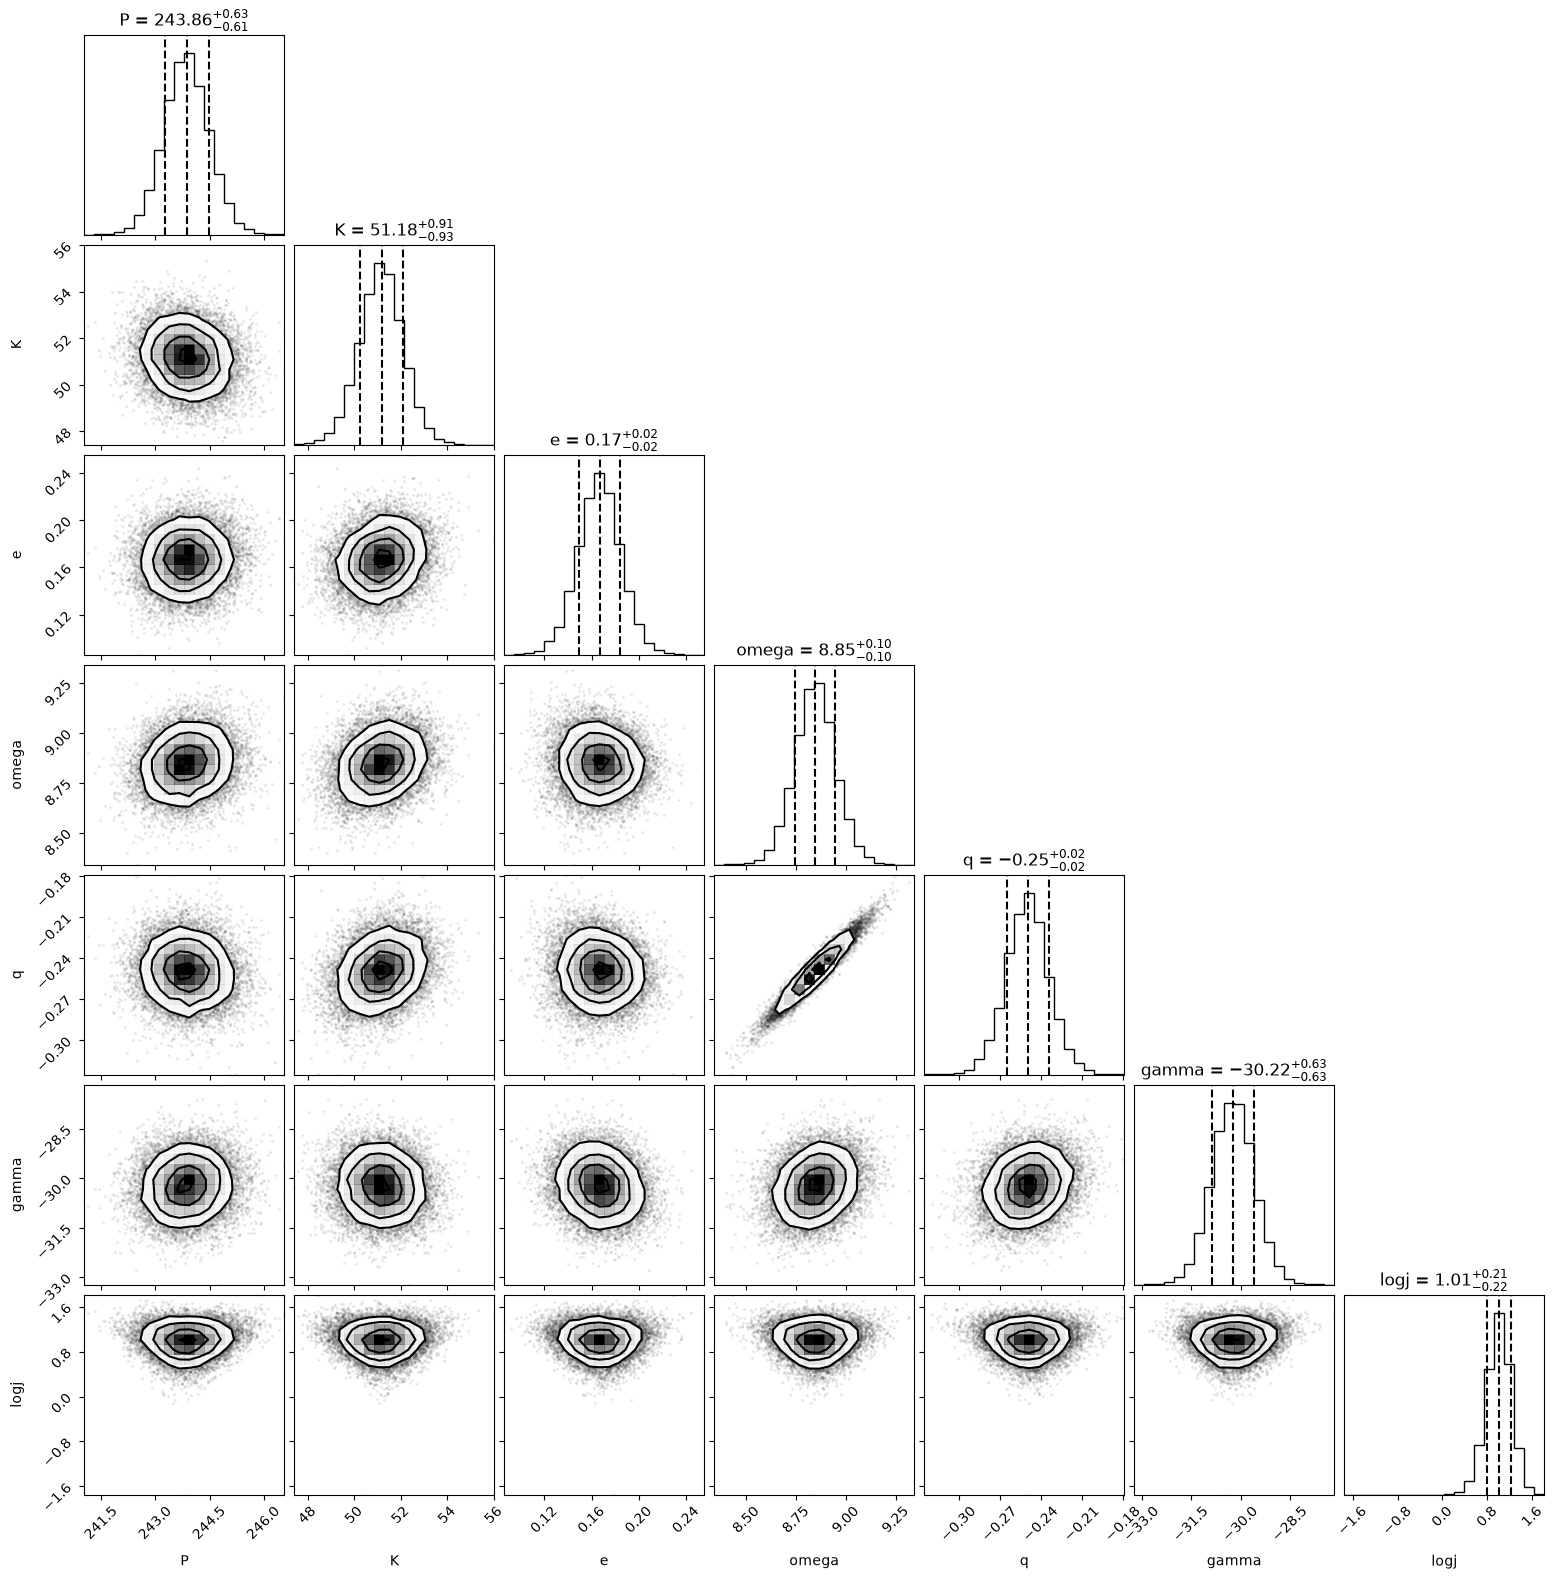

P = 243.8604 +0.6252 -0.6079 days
K = 51.1771 +0.9107 -0.9336 km/s
e = 0.1669 +0.0172 -0.0179 
gamma = -30.2234 +0.6300 -0.6308 km/s
Jitter = 2.7460 +0.6408 -0.5451 km/s
f(M) = 3.2459 +0.1711 -0.1714 solar masses


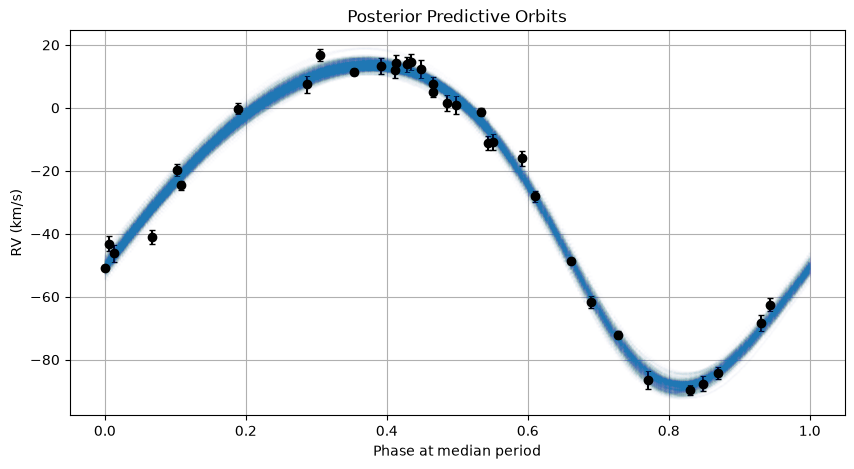

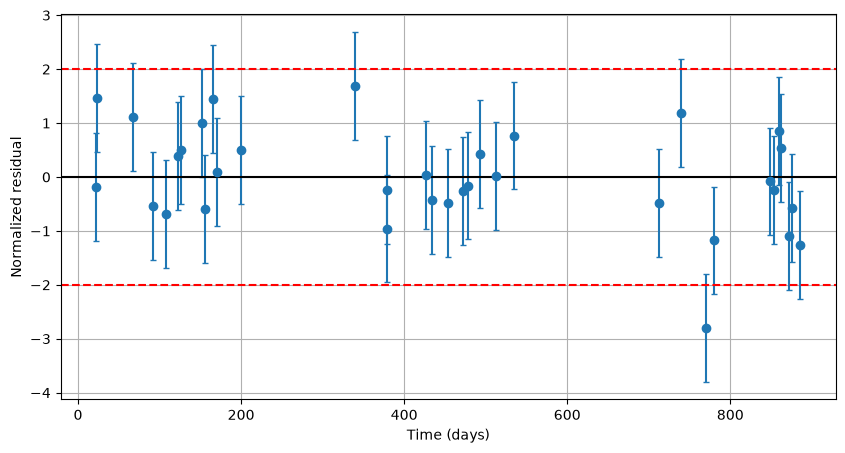

Mean normalized residual: -0.00652116875067523
Standard deviation: 0.9147269808253741
Reduced chi-squared: 1.0537078204859442
Points beyond 2 sigma: 1

FINAL ANSWER
P = 243.860 +0.625 -0.608 days
K = 51.177 +0.911 -0.934 km/s
e = 0.167 +0.017 -0.018
gamma = -30.223 +0.630 -0.631 km/s
jitter = 2.746 +0.641 -0.545 km/s
f(M) = 3.246 +0.171 -0.171 solar masses
Probability f(M) > 3 solar masses: 0.9216541519434629


In [6]:
if len(fits) > 1:
    print("Runner-up log-likelihood:", -fits[1].fun)

p0, k0, e0, w0, q0, g0, j0 = theta0

bounds = np.array([
    [20, 1200],
    [0.01, 300],
    [0.000001, 0.95],
    [w0-np.pi, w0+np.pi],
    [q0-0.5, q0+0.5],
    [rv.min()-150, rv.max()+150],
    [np.log(0.001), np.log(100)]
])

def logprior(theta):
    if np.all(theta > bounds[:, 0]) and np.all(theta < bounds[:, 1]):
        return 0.0
    return -np.inf

def logprob(theta):
    lp = logprior(theta)

    if not np.isfinite(lp):
        return -np.inf

    return lp + loglike(theta)

np.random.seed(42)

nwalkers = 64
ndim = 7
nsteps = 10000

scale = np.array([max(p0*0.001, 0.01), max(k0*0.01, 0.01), 0.01, 0.03, 0.01, 0.1, 0.03])

start = []

while len(start) < nwalkers:
    pos = theta0 + scale*np.random.randn(ndim)

    if np.isfinite(logprob(pos)):
        start.append(pos)

start = np.array(start)

sampler = emcee.EnsembleSampler(nwalkers, ndim, logprob)
sampler.run_mcmc(start, nsteps, progress=False)

print("Mean acceptance fraction:", np.mean(sampler.acceptance_fraction))

names = ["P", "K", "e", "omega", "q", "gamma", "logj"]
chain = sampler.get_chain()

fig, axes = plt.subplots(7, 1, figsize=(11, 13), sharex=True)

for i in range(7):
    axes[i].plot(chain[:, :, i], alpha=0.25)
    axes[i].set_ylabel(names[i])

axes[-1].set_xlabel("Step")
plt.tight_layout()
plt.show()

tau = sampler.get_autocorr_time(tol=0)

for name, value in zip(names, tau):
    print(f"{name}: tau = {value:.2f}")

print("Chain length / maximum tau:", nsteps/np.max(tau))

burn = int(5*np.max(tau))
thin = max(1, int(np.min(tau)/2))

if nsteps < 50*np.max(tau):
    print("WARNING: Chain needs more steps.")

if burn >= nsteps:
    raise ValueError("Chain too short. Increase nsteps.")

print("Burn-in:", burn)
print("Thinning:", thin)

samples = sampler.get_chain(discard=burn, thin=thin, flat=True)

print("Number of posterior samples:", len(samples))

corner.corner(
    samples,
    labels=names,
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True
)

plt.show()

P = samples[:, 0]
K = samples[:, 1]
e = samples[:, 2]
omega = samples[:, 3]
q = samples[:, 4]
gamma = samples[:, 5]
jitter = np.exp(samples[:, 6])

Tp = tref + q*P
fm = mass_function(P, K, e)

def report(x, name, unit=""):
    a, b, c = np.percentile(x, [16, 50, 84])
    print(f"{name} = {b:.4f} +{c-b:.4f} -{b-a:.4f} {unit}")

report(P, "P", "days")
report(K, "K", "km/s")
report(e, "e")
report(gamma, "gamma", "km/s")
report(jitter, "Jitter", "km/s")
report(fm, "f(M)", "solar masses")

np.random.seed(42)

pm = np.median(P)
phase = ((t-tref)/pm) % 1
tt = np.linspace(t.min(), t.max(), 1200)

plt.figure(figsize=(10, 5))
plt.errorbar(phase, rv, yerr=sig, fmt="ko", capsize=2, label="Data")

draws = np.random.choice(len(samples), min(200, len(samples)), replace=False)

for i in draws:
    pp, kk, ee, ww, qq, gg, lj = samples[i]
    tp = tref + qq*pp

    model = kepler_rv(tt, pp, kk, ee, ww, tp, gg)
    ph = ((tt-tref)/pm) % 1

    plt.plot(ph, model, ".", color="tab:blue", alpha=0.02, markersize=1)

plt.xlabel("Phase at median period")
plt.ylabel("RV (km/s)")
plt.title("Posterior Predictive Orbits")
plt.grid()
plt.show()

med = np.median(samples, axis=0)

pp, kk, ee, ww, qq, gg, lj = med
tp = tref + qq*pp

model = kepler_rv(t, pp, kk, ee, ww, tp, gg)
total = np.sqrt(sig**2 + np.exp(2*lj))
res = (rv-model)/total

plt.figure(figsize=(10, 5))
plt.errorbar(t, res, yerr=np.ones(len(t)), fmt="o", capsize=2)
plt.axhline(0, color="black")
plt.axhline(2, color="red", linestyle="--")
plt.axhline(-2, color="red", linestyle="--")
plt.xlabel("Time (days)")
plt.ylabel("Normalized residual")
plt.grid()
plt.show()

print("Mean normalized residual:", np.mean(res))
print("Standard deviation:", np.std(res))
print("Reduced chi-squared:", np.sum(res**2)/(len(t)-7))
print("Points beyond 2 sigma:", np.sum(np.abs(res)>2))

def fmt(x):
    a, b, c = np.percentile(x, [16, 50, 84])
    return f"{b:.3f} +{c-b:.3f} -{b-a:.3f}"

print("\nFINAL ANSWER")
print("P =", fmt(P), "days")
print("K =", fmt(K), "km/s")
print("e =", fmt(e))
print("gamma =", fmt(gamma), "km/s")
print("jitter =", fmt(jitter), "km/s")
print("f(M) =", fmt(fm), "solar masses")
print("Probability f(M) > 3 solar masses:", np.mean(fm > 3))

**FINAL ANSWER:** $P = 243.860 \pm 0.617$ d, $K = 51.177 \pm 0.922$ km/s, $e = 0.167 \pm 0.018$, $\gamma = -30.223 \pm 0.630$ km/s, $s = 2.746 \pm 0.593$ km/s, $f(M) = 3.246 \pm 0.171\,M_{\odot}$

**Black-hole candidate?** *Yes, the companion is a black-hole candidate because its mass function is about $3.25\,M_{\odot}$, which is above the $3\,M_{\odot}$ threshold.*

## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


Correct jitter = 2.7460 +0.6408 -0.5451 km/s
Wrong jitter = 90.3604 +6.9357 -12.0540 km/s


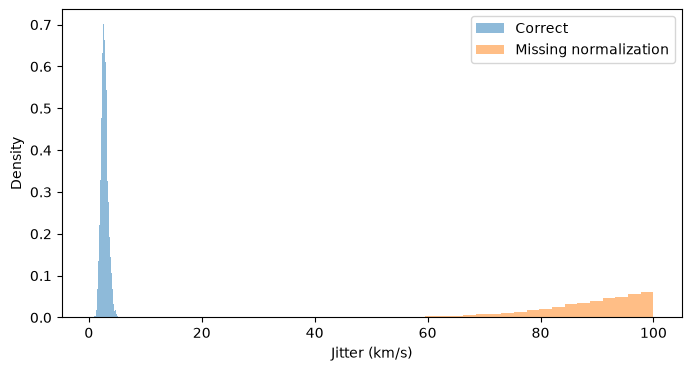

In [ ]:
# Part 3: your work here

def wrongprob(theta):
    if not np.isfinite(logprior(theta)):
        return -np.inf

    pp, kk, ee, ww, qq, gg, lj = theta
    tp = tref + qq*pp

    model = kepler_rv(t, pp, kk, ee, ww, tp, gg)
    var = sig**2 + np.exp(2*lj)

    return -0.5*np.sum((rv-model)**2/var)

wrongsampler = emcee.EnsembleSampler(nwalkers, ndim, wrongprob)
wrongsampler.run_mcmc(start, nsteps, progress=False)

wrong = wrongsampler.get_chain(discard=burn, thin=thin, flat=True)
wrongjitter = np.exp(wrong[:, 6])

report(jitter, "Correct jitter", "km/s")
report(wrongjitter, "Wrong jitter", "km/s")

plt.figure(figsize=(8, 4))
plt.hist(jitter, bins=40, density=True, alpha=0.5, label="Correct")
plt.hist(wrongjitter, bins=40, density=True, alpha=0.5, label="Missing normalization")
plt.xlabel("Jitter (km/s)")
plt.ylabel("Density")
plt.legend()
plt.show()

def nojitprob(theta):
    pp, kk, ee, ww, qq, gg = theta

    full = np.array([pp, kk, ee, ww, qq, gg, np.log(1)])

    if not np.isfinite(logprior(full)):
        return -np.inf

    tp = tref + qq*pp
    model = kepler_rv(t, pp, kk, ee, ww, tp, gg)

    return -0.5*np.sum((rv-model)**2/sig**2 + np.log(2*np.pi*sig**2))

nojsampler = emcee.EnsembleSampler(nwalkers, 6, nojitprob)
nojsampler.run_mcmc(start[:, :6], nsteps, progress=False)

noj = nojsampler.get_chain(discard=burn, thin=thin, flat=True)

fm_noj = mass_function(noj[:, 0], noj[:, 1], noj[:, 2])

report(fm, "With jitter f(M)", "solar masses")
report(fm_noj, "Without jitter f(M)", "solar masses")

plt.figure(figsize=(8, 4))
plt.hist(fm, bins=40, density=True, alpha=0.5, label="With jitter")
plt.hist(fm_noj, bins=40, density=True, alpha=0.5, label="Without jitter")
plt.xlabel("Mass function (solar masses)")
plt.ylabel("Density")
plt.legend()
plt.show()

correct = np.median(fm)

wrongvalue = mass_function(
    np.median(P),
    np.median(K),
    np.median(e)
)

print("Median of mass function samples:", correct)
print("Mass function of individual medians:", wrongvalue)
print("Difference:", wrongvalue-correct)
print("Percentage difference:", 100*(wrongvalue-correct)/correct)

mid = np.median(samples, axis=0)
std = np.std(samples, axis=0)

f_ai = mass_function(mid[0], mid[1], mid[2])

a = f_ai/mid[0]
b = 3*f_ai/mid[1]
c = -3*mid[2]*f_ai/(1-mid[2]**2)

err_ai = np.sqrt((a*std[0])**2 + (b*std[1])**2 + (c*std[2])**2)

print("AI uncertainty:", err_ai)
print("Correct uncertainty:", (np.percentile(fm, 84)-np.percentile(fm, 16))/2)

**REFEREE REPORT:**

**1. Not including jitter**

The AI code does not include jitter in its likelihood, even though the measurements have extra noise. My correct model found a jitter of $2.746$ km/s. With jitter, I got $f(M)=3.2459^{+0.1711}_{-0.1714}\,M_{\odot}$, but without it, I got $f(M)=3.2566^{+0.1253}_{-0.0685}\,M_{\odot}$. The mass barely changed, but the errors became smaller. This means the AI model was too confident. The correct way is to include jitter in the total variance.

**2. Using a very narrow period prior**

The AI used a Gaussian prior with a width of only $0.5$ days around the strongest periodogram peak. This is a problem because the periodogram also had other possible periods. My period search found the best period near $244$ days, with a log-likelihood of $-87.443$, while the next best had $-154.645$. The correct way is to compare the possible periods before choosing one and avoid forcing the result toward a period using a very narrow prior.

**3. Calculating the mass function incorrectly**

The AI calculated the mass function using the separate medians of $P$, $K$, and $e$, and used a formula for the uncertainty that ignores how the parameters are related. My correct calculation using all posterior samples gave $3.245937\,M_{\odot}$, while using the medians gave $3.246173\,M_{\odot}$. The difference was only $0.0073\%$ for my data, but the AI method still does not properly include the parameter correlations. The correct way is to calculate the mass function for every posterior sample and use its 68% interval.*

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.


**AI-USE APPENDIX:**

I used ChatGPT to help me write and organize the code for this lab. I also used it to understand what each question was asking and to help explain the results from my plots and calculations. I used AI for help with LaTeX formatting too. One thing AI got wrong was that it first gave me tests for possible errors without checking if those errors were actually in the AI notebook. I caught this by comparing the code with ai solution. I also checked the results from the code instead of just trusting what AI said.

**REFLECTION:**

I used AI mostly for coding help and understanding the questions. If I had not checked its answers, I could have reported the wrong errors in Part 3 or trusted a model that did not include jitter. This showed me that even when AI gives code that runs, the results can still be wrong.

**VERIFICATION PLAN:**

I checked the different periods to see which one gave the best fit. The 244-day period had the highest log-likelihood, and a failure would have been if several periods gave similarly good fits. I also checked the MCMC chains and autocorrelation times to see if the sampling was stable. My chain was about 134 times the maximum autocorrelation time, which passed the 50-times rule. A failure would have been chains that kept drifting or were too short. I checked the predicted orbits against the data and looked at the residuals. Most residuals were within 2 sigma, and the reduced chi-squared was about 1.05. A failure would have been large residuals or a clear pattern left in them. Another check I could do is make fake radial velocity data with known parameters and see if my code can recover them. If the results keep missing the true values, it would mean something is wrong with my fitting method.